# 0.2 Benchmarks

Where do our lab datasets (`data/interim/extracted/`) sit against **mycelium products** (Ecovative, its licensees and the other companies first listed in `MycoMaterials/mycomaterials_benchmarks.xlsx`) and against the **conventional materials** those products try to replace (foams, insulation boards, wood, bricks, leather)?

**Families** (column `family`, one colour each): `eco` = Ecovative and its licensees (orange), `other` = other mycelium companies (green), `lab` = lab mycelium values not in our extracted tables (blue, like our data), `standard` = conventional materials (grey).

**Product type** (column `category`): kit, packaging, board, acoustic panel, insulation, leather, block / brick, solid wood, foam, tissue, lab composite, general. In the charts a mycelium product's marker shape shows its type; conventional materials are grey boxes with their name.

**Status of each value** (column `status`)
- `checked`: read directly on the maker's page or data sheet, in the patent text, in a handbook or in a paper.
- `patent`: Gemini found it in an uploaded patent and gave an exact quote (`MycoMaterials/Germini/germini_r1.xlsx` and `patent_benchmark_verification_notes.md`, 2026-10-11).
- `no_source`: no patent or primary source found. Kept in the table, left off the charts.

**Reference** (columns `ref` and `where`): the key of the full reference at the end (P = patent, R = paper or review, W = mycelium maker's page, S = conventional material source), and where in it the value sits.

**Kind of value** (column `kind`): `measured` is a test result or worked example; `claim` is a claimed or preferred range in a patent (drawn dashed); `declared` is the value a maker declares for a conventional product under its product standard (for example EN 13163 for EPS).

Commercial and conventional figures are reference marks, never model training rows.

### The charts in this notebook

| # | Chart | What is on it | How to read it | Watch out for |
|---|---|---|---|---|
| 3 | Density against compressive strength | our lab blocks (dots), mycelium products (shaped markers), conventional materials (grey boxes) | further up = stronger, further right = heavier; a material is "better" if it is up and to the left | strain differs: ours, Mogu, Grown.bio and the insulation boards are at 10%; GIY at 15%; wood, AAC and brick are maximum strength |
| 3b | The same, coloured by product category | the same points; one colour per product type, lab and test blocks light grey | compare a mycelium product with the conventional material of the same colour | same as 3 |
| 4 | Growth time and temperature | lab studies and commercial processes | how long and how warm each one grows | kits use thin parts and pre-colonised material |
| 5 | Tensile strength | mycelium leathers against cow leather and PU artificial leather | how hard you can pull before it tears | patent claims are what was protected, not what was made |
| 6 | Density against thermal conductivity | mycelium products, lab composites, insulation boards, blocks | lower = better insulation | our extracted tables have no thermal values yet |
| 7 | Sound absorption | Mogu panels against PET felt panels | closer to 1 = absorbs more echo | both mounted directly on the wall; a gap behind raises both |

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

from mycodemo.config import INTERIM_DATA_DIR

EXTRACTED_DIR = INTERIM_DATA_DIR / "extracted"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# One colour per source family; each of our studies gets its own colour and marker shape
OURS, ECO, OTHER, STANDARD = "#2a78d6", "#eb6834", "#008300", "#80858c"
FAMILY_COLOUR = {"eco": ECO, "other": OTHER, "lab": OURS, "standard": STANDARD}
FAMILY_ORDER = ["eco", "other", "lab", "standard"]  # order of rows in the bar charts
# Marker shape of a mycelium product by its category (conventional materials are grey boxes)
CATEGORY_MARKER = {"kit": "D", "packaging": "X", "board": "P", "acoustic panel": "*", "leather": "h"}
# Colour per product category, for the chart coloured by category; lab and test materials are light grey
LAB_GREY = "#c9ccd1"
CATEGORY_COLOUR = {"kit": "#e69f00", "packaging": "#d55e00", "board": "#009e73", "acoustic panel": "#cc79a7",
                   "insulation": "#0072b2", "solid wood": "#8c6d31", "block / brick": "#b2182b",
                   "leather": "#6a3d9a", "foam": "#56b4e9", "tissue": "#999933", "general": "#666666",
                   "lab composite": LAB_GREY}
DATASET_STYLE = {  # colour, marker
    "d004": ("#2a78d6", "o"),
    "d005": ("#1baf7a", "s"),
    "d007": ("#6250d6", "^"),
    "d016": ("#e87ba4", "v"),
}
NAMES = {
    "d002": "Musci 2025", "d003": "Gomaa 2024", "d004": "Bhaskar 2026", "d005": "Elsacker 2019",
    "d006": "Hysek 2025", "d007": "Irbe 2026", "d009": "Elsacker 2022", "d016": "Vašatko 2022",
    "d012": "Pacheco-Sanchez 2026", "d017": "Jiménez-Obando 2025",
    "d023": "Houette 2022",
}

## 1. Benchmark values

Typed in here rather than kept as a new CSV. **One row per benchmark**, with one column pair per property and the unit in the column name: `density_kg_m3`, `stress_MPa` (compressive), `tensile_MPa`, `days`, `temp_C`, `thermal_W_mK` (thermal conductivity λ) and `alpha_w` (weighted sound absorption, no unit). An empty cell means the source gives no value. `_lo` = `_hi` means a single value; an empty `_hi` with a filled `_lo` means the source gives only a lower limit (">").

When a product has both a claimed range and a measured example from the same source, they are two rows (for example "SQIM ephea, claim" and "SQIM ephea, example"), so `kind` and `status` always describe the whole row. GIY conversions: 7.6 lb/ft³ ≈ 122 kg/m³, 18 psi ≈ 0.124 MPa. Wood densities are specific gravity × 1000.

In [ ]:
# One row per benchmark (a product, or one claim/example within a product).
# Each property has its own column pair with the unit in the name; empty = the source gives no value.
# _lo = _hi means a single value; an empty _hi with a filled _lo means "more than" (lower limit only).
PROPS = ["density_kg_m3", "stress_MPa", "tensile_MPa", "days", "temp_C", "thermal_W_mK", "alpha_w"]
cols = (["benchmark", "maker", "family", "category", "kind", "status", "ref", "where"]
        + [f"{p}_{e}" for p in PROPS for e in ("lo", "hi")]
        + ["note"])

rows = [
    # Ecovative and its GIY kit
    dict(benchmark="GIY kit material", maker="Ecovative", family="eco", category="kit", kind="measured", status="checked",
         ref="W1, W3", where="product page; FAQ",
         density_kg_m3_lo=122, density_kg_m3_hi=122, stress_MPa_lo=0.124, stress_MPa_hi=0.124,
         note="maker's spec, no replicates; stress at 15% strain; flexural 0.23 MPa; dries to 35% of original weight, shrinks 4% (X, Y) and 7% (Z)"),
    dict(benchmark="GIY kit", maker="Ecovative", family="eco", category="kit", kind="measured", status="checked",
         ref="W2, W3", where="instructions; FAQ",
         days_lo=7, days_hi=10, temp_C_lo=22, temp_C_hi=22,
         note="thin parts, pre-colonised material; about 7 d from hydrated, 10 d from dehydrated material"),
    dict(benchmark="Grown.bio kit (EU licensee)", maker="Ecovative", family="eco", category="kit", kind="measured", status="checked",
         ref="W4", where="steps 3 and 4",
         days_lo=6, days_hi=7, temp_C_lo=22, temp_C_hi=26, note="4–5 d in mould + 2 d out"),
    dict(benchmark="Grown.bio packaging", maker="Grown.bio (Ecovative licensee)", family="eco", category="packaging",
         kind="measured", status="checked", ref="W6", where="material data sheet",
         density_kg_m3_lo=115.5, density_kg_m3_hi=115.5, stress_MPa_lo=0.0021, stress_MPa_hi=0.046,
         thermal_W_mK_lo=0.0576, thermal_W_mK_hi=0.0576,
         note="maker's sheet; stress at 10% compression (ASTM D695); mechanical and thermal tests by Ecovative's own lab, density by AVANS, fire Class A by RIT; small commercial maker"),
    dict(benchmark="Ecovative grown materials", maker="Ecovative", family="eco", category="general", kind="measured", status="checked",
         ref="P2", where="Examples 4 and 6",
         days_lo=14, days_hi=14, temp_C_lo=24, temp_C_hi=24, note="P. ostreatus, 75 °F, 100% RH"),
    dict(benchmark="Ecovative moulded packaging, claim", maker="Ecovative", family="eco", category="packaging", kind="claim", status="patent",
         ref="P3", where="operating parameters table",
         days_lo=3, days_hi=12, note="worked example 5 + 4 = 9 days"),
    dict(benchmark="Ecovative moulded packaging, example", maker="Ecovative", family="eco", category="packaging", kind="measured", status="patent",
         ref="P3", where="operating parameters table",
         temp_C_lo=18, temp_C_hi=24, note="65 °F cooled air, 75 °F air; vessel below 35 °C"),
    dict(benchmark="Ecovative moulded packaging, review figures", maker="Ecovative", family="eco", category="packaging", kind="claim", status="no_source",
         ref="", where="review literature per Gemini (Jones 2017, Girometta 2019)",
         density_kg_m3_lo=50, density_kg_m3_hi=250, stress_MPa_lo=0.2, stress_MPa_hi=1.5,
         thermal_W_mK_lo=0.040, thermal_W_mK_hi=0.040, note="not in P3"),
    dict(benchmark="Ecovative AirMycelium", maker="Ecovative", family="eco", category="foam", kind="claim", status="checked",
         ref="R1", where="section on aerial mycelium",
         temp_C_lo=30, temp_C_hi=32, note="process described from Ecovative patents"),
    dict(benchmark="Ecovative AirMycelium, unverified", maker="Ecovative", family="eco", category="foam", kind="claim", status="no_source",
         ref="", where="Gemini; not found in R1",
         density_kg_m3_lo=10, density_kg_m3_hi=800, days_lo=9, days_hi=14,
         note="10–150 kg/m³ loose, 400–800 pressed"),
    dict(benchmark="Ecovative fruiting-body shapes", maker="Ecovative", family="eco", category="tissue", kind="measured", status="patent",
         ref="P1", where="Examples 1 and 2",
         days_lo=28, days_hi=75, temp_C_lo=21, temp_C_hi=24, note="21–45 d incubation + 7–30 d fruiting"),
    dict(benchmark="Raw fruiting-body tissue", maker="Ecovative", family="eco", category="tissue", kind="measured", status="patent",
         ref="P1", where="col. 1",
         density_kg_m3_lo=180, density_kg_m3_hi=390,
         note="cap 180, stipe up to 350, spore tubes 340–390; tissue, not composite"),
    # Other companies
    dict(benchmark="Mogu acoustic panels", maker="Mogu / SQIM", family="other", category="acoustic panel",
         kind="measured", status="checked", ref="W5", where="technical datasheet",
         density_kg_m3_lo=120, density_kg_m3_hi=120, stress_MPa_lo=0.0107, stress_MPa_hi=0.0107,
         thermal_W_mK_lo=0.050, thermal_W_mK_hi=0.050, alpha_w_lo=0.30, alpha_w_hi=0.35,
         note="maker's sheet, no test lab named; stress at 10% (EN 826, same metric as ours); λ at 40 mm (EN 12664-2); αw bare on the wall (ISO 11654), 0.45–0.50 with insulation behind; fire B-s2-d0; sold commercially"),
    dict(benchmark="Okom Wrks boards", maker="Okom Wrks", family="other", category="board", kind="claim", status="patent",
         ref="P7", where="claims 1, 2, 12–14 and 19",
         density_kg_m3_lo=250, stress_MPa_lo=1.2, days_lo=4, days_hi=17, temp_C_lo=22, temp_C_hi=26,
         note="> 0.25 g/cm³ and > 1.2 MPa ultimate compressive strength (lower limits only)"),
    dict(benchmark="Okom Wrks example", maker="Okom Wrks", family="other", category="board", kind="measured", status="patent",
         ref="P7", where="Example 1",
         density_kg_m3_lo=250, density_kg_m3_hi=250, stress_MPa_lo=0.98, stress_MPa_hi=0.98,
         note="hollow cylinder, n = 1; strain not given; below its own 1.2 MPa claim"),
    dict(benchmark="Processed mycelium leather", maker="Bolt Threads; BLC Leather Technology Centre", family="other",
         category="leather", kind="measured", status="patent", ref="P4", where="Table 1",
         density_kg_m3_lo=620, density_kg_m3_hi=621, tensile_MPa_lo=2.87, tensile_MPa_hi=3.69,
         note="G. sessile mats; tensile = means of treatments A and B (SD 1.3–1.4), n = 42 and 47"),
    dict(benchmark="MuSkin", maker="Grado Zero Espace", family="other", category="leather",
         kind="measured", status="checked", ref="R2", where="Table 2",
         tensile_MPa_lo=0.2, tensile_MPa_hi=0.2,
         note="independent test (FILK, ISO 3376); 6.2 mm thick; samples donated by the German Leather Association"),
    dict(benchmark="SQIM ephea, uncoated", maker="Mogu / SQIM", family="other", category="leather", kind="claim", status="patent",
         ref="P5", where="p. 6", tensile_MPa_lo=0.5, tensile_MPa_hi=5, note="ISO 3376"),
    dict(benchmark="SQIM ephea, coated", maker="Mogu / SQIM", family="other", category="leather", kind="claim", status="patent",
         ref="P5", where="p. 8", tensile_MPa_lo=8, tensile_MPa_hi=50, note="coating about 8× stronger in Example 4"),
    dict(benchmark="SQIM ephea, claim", maker="Mogu / SQIM", family="other", category="leather", kind="claim", status="patent",
         ref="P5", where="p. 5", days_lo=10, days_hi=18, note="preferred mat incubation; Example 2 used 14 d"),
    dict(benchmark="SQIM ephea, example", maker="Mogu / SQIM", family="other", category="leather", kind="measured", status="patent",
         ref="P5", where="Example 2", temp_C_lo=23, temp_C_hi=28),
    dict(benchmark="Bolt Threads Mylo", maker="Bolt Threads", family="other", category="leather", kind="claim", status="patent",
         ref="P6", where="paras. 0120 and 0148",
         tensile_MPa_lo=5, tensile_MPa_hi=30, temp_C_lo=20, temp_C_hi=35,
         note="wet tensile strength; growth days not stated; Mylo production paused in 2023"),
    dict(benchmark="Ford plasticised composites", maker="Ford", family="other", category="general", kind="claim", status="patent",
         ref="P8", where="cols. 4 and 7",
         days_lo=1, days_hi=15, temp_C_lo=13, temp_C_hi=32, note="55–90 °F"),
    dict(benchmark="MycoWorks Fine Mycelium", maker="MycoWorks", family="other", category="leather", kind="claim", status="no_source",
         ref="", where="Gemini; tensile not found, days not in R1",
         tensile_MPa_lo=10, tensile_MPa_hi=25, days_lo=14, days_hi=18,
         note="factory shut and company liquidated in 2025"),
    dict(benchmark="Mushroom Material pellets", maker="Mushroom Material", family="other", category="packaging", kind="claim", status="no_source",
         ref="", where="news release per Gemini",
         density_kg_m3_lo=40, density_kg_m3_hi=120, days_lo=6, days_hi=8),
    dict(benchmark="Biohm MycoPanel", maker="Biohm", family="other", category="insulation", kind="claim", status="no_source",
         ref="", where="marketing per Gemini", thermal_W_mK_lo=0.024, thermal_W_mK_hi=0.024,
         note="below still air (~0.026): likely wrong"),
    dict(benchmark="Mykor MykoFoam", maker="Mykor", family="other", category="insulation", kind="claim", status="no_source",
         ref="", where="Innovate UK case study per Gemini", thermal_W_mK_lo=0.030, thermal_W_mK_hi=0.030),
    dict(benchmark="Loop Living Cocoon", maker="Loop Biotech", family="other", category="general", kind="claim", status="no_source",
         ref="", where="product page per Gemini", days_lo=7, days_hi=7),
    # Lab mycelium values that are not in our extracted tables
    dict(benchmark="Elsacker 2019 composites", maker="VUB lab (our d005)", family="lab", category="lab composite",
         kind="measured", status="checked", ref="R3", where="abstract; thermal conductivity section",
         density_kg_m3_lo=60, density_kg_m3_hi=187, thermal_W_mK_lo=0.0404, thermal_W_mK_hi=0.0578,
         note="T. versicolor on hemp, flax, straw, pine; λ by needle probe (ASTM D5334): hemp 0.040, straw 0.042, flax 0.058"),
    # Conventional materials (declared values on maker sheets, or handbook values)
    dict(benchmark="EPS foam (EPS 70–100)", maker="Sundolitt", family="standard", category="insulation",
         kind="declared", status="checked", ref="S1", where="data sheet, grades CE70 and CE100",
         density_kg_m3_lo=15, density_kg_m3_hi=20, stress_MPa_lo=0.07, stress_MPa_hi=0.10,
         thermal_W_mK_lo=0.031, thermal_W_mK_hi=0.031,
         note="EN 13163, stress at 10%; the same foam is used as packaging; EPS 200 reaches 0.20 MPa"),
    dict(benchmark="XPS board", maker="Ravatherm", family="standard", category="insulation",
         kind="declared", status="checked", ref="S2", where="data sheet, XPS X H LB",
         density_kg_m3_lo=32, density_kg_m3_hi=32, stress_MPa_lo=0.30, stress_MPa_hi=0.30,
         thermal_W_mK_lo=0.030, thermal_W_mK_hi=0.031, note="EN 13164, stress at 10% (EN 826)"),
    dict(benchmark="PIR board", maker="Utherm", family="standard", category="insulation",
         kind="declared", status="checked", ref="S3", where="data sheet, Roof LE LS",
         density_kg_m3_lo=32, density_kg_m3_hi=32, stress_MPa_lo=0.15, stress_MPa_hi=0.15,
         thermal_W_mK_lo=0.022, thermal_W_mK_hi=0.022, note="EN 13165, stress at 10% (EN 826)"),
    dict(benchmark="Stone wool board", maker="Rockwool", family="standard", category="insulation",
         kind="declared", status="checked", ref="S4", where="data sheet, Fabrock 120",
         density_kg_m3_lo=144, density_kg_m3_hi=144, stress_MPa_lo=0.030, stress_MPa_hi=0.030,
         thermal_W_mK_lo=0.036, thermal_W_mK_hi=0.036,
         note="stress at 10% (ASTM C165); λ worked out from RSI 0.71 per 25.4 mm"),
    dict(benchmark="Wood fibre board", maker="Steico", family="standard", category="insulation",
         kind="declared", status="checked", ref="S5", where="data sheet, universal dry",
         density_kg_m3_lo=180, density_kg_m3_hi=210, stress_MPa_lo=0.20, stress_MPa_hi=0.20,
         thermal_W_mK_lo=0.043, thermal_W_mK_hi=0.045, note="EN 13171, stress at 10%"),
    dict(benchmark="Expanded cork board", maker="Amorim", family="standard", category="insulation",
         kind="declared", status="checked", ref="S6", where="material data sheet",
         density_kg_m3_lo=100, density_kg_m3_hi=120, stress_MPa_lo=0.10, stress_MPa_hi=0.10,
         thermal_W_mK_lo=0.039, thermal_W_mK_hi=0.040, note="CS(10)100: at least 0.10 MPa at 10% (EN 826), like every CS(10) class"),
    dict(benchmark="PET felt acoustic panel", maker="XAL (Xilence)", family="standard", category="acoustic panel",
         kind="declared", status="checked", ref="S11", where="felt material overview",
         density_kg_m3_lo=152, density_kg_m3_hi=211, alpha_w_lo=0.25, alpha_w_hi=0.50,
         note="9–25 mm felt directly on the wall; 0.75–0.90 with an 80 mm gap behind; density worked out from g/m² and thickness"),
    dict(benchmark="Balsa", maker="Wood Handbook", family="standard", category="solid wood",
         kind="measured", status="checked", ref="S7", where="Table 5-5a",
         density_kg_m3_lo=160, density_kg_m3_hi=160, stress_MPa_lo=14.9, stress_MPa_hi=14.9,
         note="along the grain, 12% moisture; density from specific gravity 0.16"),
    dict(benchmark="Softwood (spruce, pine, Douglas-fir)", maker="Wood Handbook", family="standard", category="solid wood",
         kind="measured", status="checked", ref="S7", where="Table 5-3a",
         density_kg_m3_lo=350, density_kg_m3_hi=480, stress_MPa_lo=3.0, stress_MPa_hi=49.9,
         note="12% moisture; low end = across the grain (proportional limit), high end = along the grain; density from specific gravity 0.35–0.48"),
    dict(benchmark="Hempcrete", maker="various", family="standard", category="block / brick",
         kind="measured", status="checked", ref="S10", where="density, strength and thermal sections",
         density_kg_m3_lo=200, density_kg_m3_hi=960, stress_MPa_lo=0.3, stress_MPa_hi=0.3,
         thermal_W_mK_lo=0.05, thermal_W_mK_hi=0.138,
         note="secondary source (Wikipedia, citing Bouloc 2013, Niyigena 2016, Dhakal 2016); not load-bearing"),
    dict(benchmark="Aircrete block (AAC)", maker="H+H", family="standard", category="block / brick",
         kind="declared", status="checked", ref="S8", where="NBS product page, Solar Grade Jumbo Block",
         density_kg_m3_lo=460, density_kg_m3_hi=460, stress_MPa_lo=2.9, stress_MPa_hi=2.9,
         thermal_W_mK_lo=0.11, thermal_W_mK_hi=0.11, note="minimum mean compressive strength"),
    dict(benchmark="Fired clay brick", maker="Floren", family="standard", category="block / brick",
         kind="declared", status="checked", ref="S9", where="NBS product page, Brigand",
         density_kg_m3_lo=1700, density_kg_m3_hi=1700, stress_MPa_lo=40, stress_MPa_hi=40,
         thermal_W_mK_lo=0.55, thermal_W_mK_hi=0.55, note="minimum mean compressive strength; EN 771-1"),
    dict(benchmark="Shoe-upper leather (cow)", maker="tested by FILK", family="standard", category="leather",
         kind="measured", status="checked", ref="R2", where="Table 2",
         tensile_MPa_lo=39.5, tensile_MPa_hi=39.5, note="1.9 mm; ISO 3376"),
    dict(benchmark="PU-coated textile (artificial leather)", maker="tested by FILK", family="standard", category="leather",
         kind="measured", status="checked", ref="R2", where="Table 2",
         tensile_MPa_lo=10.2, tensile_MPa_hi=10.2, note="1.4 mm; ISO 3376"),
]
bench = pd.DataFrame(rows, columns=cols)
shown = bench[bench.status != "no_source"]  # charts use only checked and patent values

print(bench.groupby(["family", "status"]).size().to_string())
bench

## 2. Our data: density and stress per row, growth days and temperature per dataset

In [3]:
meas = pd.read_csv(EXTRACTED_DIR / "measurement.csv")
sample = pd.read_csv(EXTRACTED_DIR / "sample.csv")
ferm = pd.read_csv(EXTRACTED_DIR / "fermentation.csv")

props = meas.rename(columns={"compressive_stress_at_10pct_strain_MPa": "stress",
                             "dry_density_kg_m3": "density"})
both = props.dropna(subset=["stress", "density"])
dens = props.dropna(subset=["density"])

growth = (sample.merge(ferm, on="fermentation_id")
          .groupby("dataset_id")[["total_growth_days", "incubation_temp_c"]]
          .agg(["min", "max"]))
growth.columns = ["days_lo", "days_hi", "temp_lo", "temp_hi"]

print(f"{len(both)} rows have both density and stress, from {both.dataset_id.nunique()} datasets")
print(f"{len(dens)} rows have density, from {dens.dataset_id.nunique()} datasets")
growth

108 rows have both density and stress, from 4 datasets
187 rows have density, from 7 datasets


,days_lo,days_hi,temp_lo,temp_hi
dataset_id,,,,
d002,28.0,28.0,24.0,24.0
d003,13.0,13.0,28.0,28.0
d004,14.0,14.0,NaN,NaN
d005,16.0,19.0,24.0,28.0
d006,29.0,29.0,24.0,24.0
d007,21.0,21.0,22.0,22.0
d009,22.0,22.0,26.0,26.0
d012,NaN,NaN,19.0,19.0
d016,14.0,17.0,NaN,NaN


### Drawing helpers

Shared by the charts below: grey boxes for conventional materials, shaped markers for mycelium products, and horizontal range bars.

In [ ]:
def span(r, prop, edge):
    """Low and high value of one property; an empty _hi ("more than") runs to the chart edge."""
    lo, hi = r[f"{prop}_lo"], r[f"{prop}_hi"]
    return lo, (edge if pd.isna(hi) else hi)


def draw_benchmarks(ax, xprop, yprop, xmax, ymax, offsets={}, colour_of=None):
    """Every shown benchmark with both properties, on a log-log chart.
    Conventional materials: grey box with its name. Mycelium products and lab values: a marker shaped
    by category (a range in one property becomes a line, a range in both a box). Claims are dashed.
    colour_of: optional function row -> colour (default: one colour per family)."""
    b = shown.dropna(subset=[f"{xprop}_lo", f"{yprop}_lo"])
    for _, r in b.iterrows():
        (x0, x1), (y0, y1) = span(r, xprop, xmax), span(r, yprop, ymax)
        colour = colour_of(r) if colour_of else FAMILY_COLOUR[r.family]
        dashed = r.kind == "claim"
        dx, dy = offsets.get(r.benchmark, (6, 4))
        if r.family == "standard" or (x1 > x0 and y1 > y0):
            if r.family == "standard":  # pad single values so every material shows as a small box
                x0, x1 = (x0 / 1.08, x1 * 1.08) if x0 == x1 else (x0, x1)
                y0, y1 = (y0 / 1.12, y1 * 1.12) if y0 == y1 else (y0, y1)
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=colour,
                                   alpha=0.06 if dashed else 0.18, edgecolor=colour,
                                   ls="--" if dashed else "-", lw=1.2, zorder=1))
            ax.annotate(r.benchmark, (x0, y1), xytext=(dx, dy), textcoords="offset points",
                        fontsize=8, color=colour if r.family != "standard" else "#555a60", va="bottom")
            continue
        xm, ym = np.sqrt(x0 * x1), np.sqrt(y0 * y1)  # middle on a log axis
        if x1 > x0 or y1 > y0:
            ax.plot([x0, x1], [y0, y1], color=colour, lw=2, ls="--" if dashed else "-", zorder=4)
        ax.scatter([xm], [ym], marker=CATEGORY_MARKER.get(r.category, "o"), s=130, c=colour,
                   edgecolors="white", linewidths=1.5, zorder=5)
        ax.annotate(f"{r.benchmark} ({r.category})", (xm, ym), xytext=(dx, dy),
                    textcoords="offset points", fontsize=8.5, color=colour, zorder=6)


def log_axes(ax, xticks, yticks):
    ax.set(xscale="log", yscale="log", xlim=(xticks[0], xticks[-1]), ylim=(yticks[0], yticks[-1]))
    ax.set_xticks(xticks, [f"{v:g}" for v in xticks])
    ax.set_yticks(yticks, [f"{v:g}" for v in yticks])
    ax.minorticks_off()
    ax.grid(True, which="major", color="#e6e8e3", lw=0.8)


def range_rows(ax, items, xmax, invert=True):
    """One horizontal bar (or dot) per item; items are (label, lo, hi, colour, dashed)."""
    for i, (label, lo, hi, colour, dashed) in enumerate(items):
        if pd.isna(lo):
            continue
        open_hi = pd.isna(hi)
        hi = xmax if open_hi else hi
        if lo == hi:
            ax.scatter([lo], [i], c=colour, s=45, zorder=3, edgecolors="white")
        else:
            ax.barh(i, hi - lo, left=lo, height=0.5,
                    color=colour, alpha=0.15 if dashed else 0.85,
                    edgecolor=colour, ls="--" if dashed else "-", lw=1.3)
        if open_hi:
            ax.annotate("", (xmax, i), (xmax * 0.9 if ax.get_xscale() == "log" else xmax - 1, i),
                        arrowprops=dict(arrowstyle="->", color=colour))
    ax.set_yticks(range(len(items)), [it[0] for it in items])
    if invert:  # only once per shared y-axis
        ax.invert_yaxis()
    ax.grid(True, axis="x", color="#e6e8e3", lw=0.8)


def bench_items(prop):
    """Benchmark rows for one property, as range_rows items (claims dashed),
    sorted mycelium companies first, then lab, then conventional materials; by category within each."""
    b = shown.dropna(subset=[f"{prop}_lo"]).copy()
    b["order"] = b.family.map(FAMILY_ORDER.index)
    b = b.sort_values(["order", "category"], kind="stable")
    return [(f"{r.benchmark} [{r.category}]", r[f"{prop}_lo"], r[f"{prop}_hi"],
             FAMILY_COLOUR[r.family], r.kind == "claim") for _, r in b.iterrows()]

## 3. Density against compressive strength

Both axes are logarithmic: each grid step multiplies the value, so materials 1,000 times stronger still fit on one chart. Our values are stress at 10% strain. Hollow markers are group means, filled markers single blocks.

In [ ]:
fig, ax = plt.subplots(figsize=(11, 7.5))
log_axes(ax, [10, 20, 50, 100, 200, 500, 1000, 2500],
         [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
ax.set(xlabel="Dry density (kg/m³)", ylabel="Compressive stress (MPa)")

# Benchmarks: conventional materials as grey boxes, mycelium products as markers
STRENGTH_OFFSETS = {
    "Okom Wrks boards": (4, -14), "Okom Wrks example": (8, -12), "GIY kit material": (-150, 6),
    "Grown.bio packaging": (-190, -16), "Mogu acoustic panels": (8, -4),
    "EPS foam (EPS 70–100)": (-6, 3), "PIR board": (-20, 3), "XPS board": (-6, 3),
    "Expanded cork board": (-60, 3), "Stone wool board": (-30, -22), "Wood fibre board": (4, 3)}
draw_benchmarks(ax, "density_kg_m3", "stress_MPa", 2500, 100, offsets=STRENGTH_OFFSETS)

# Our studies
for ds, (colour, marker) in DATASET_STYLE.items():
    d = both[both.dataset_id == ds]
    raw, mean = d[d.measurement_type == "raw"], d[d.measurement_type == "mean"]
    ax.scatter(raw.density, raw.stress, c=colour, marker=marker, s=28, alpha=0.8,
               edgecolors="white", linewidths=0.5, zorder=3)
    ax.scatter(mean.density, mean.stress, facecolors="none", edgecolors=colour,
               marker=marker, s=42, linewidths=1.3, zorder=3)

handles = [Line2D([], [], ls="", marker=m, color=c, label=f"{NAMES[ds]} (n={len(both[both.dataset_id == ds])})")
           for ds, (c, m) in DATASET_STYLE.items()]
handles += [Line2D([], [], ls="", marker="o", mfc="none", color="grey", label="hollow = group mean"),
            Line2D([], [], ls="", marker="s", ms=8, color=ECO, label="Ecovative and licensees"),
            Line2D([], [], ls="", marker="s", ms=8, color=OTHER, label="other mycelium companies"),
            Patch(facecolor=STANDARD, alpha=0.3, edgecolor=STANDARD, label="conventional material"),
            Patch(facecolor="none", edgecolor="grey", ls="--", label="claimed range (patent)")]
cats = shown[(shown.family != "standard")].dropna(subset=["density_kg_m3_lo", "stress_MPa_lo"]).category.unique()
handles += [Line2D([], [], ls="", marker=CATEGORY_MARKER[c], ms=8, color="#555a60", label=f"shape: {c}")
            for c in cats if c in CATEGORY_MARKER]
ax.legend(handles=handles, loc="upper left", fontsize=8.5, frameon=False)
ax.set_title("Density against compressive strength: lab, mycelium products, conventional materials",
             loc="left", fontweight="bold")
plt.show()

**What it shows:** mycelium sits in the same density band as the natural insulation boards (about 50–300 kg/m³). At the same density our blocks are stronger than stone wool, about as strong as wood fibre board and a little weaker than cork. Plastic foams (EPS, PIR, XPS) reach the same 0.1–0.3 MPa at a tenth of the weight. The products sit low: Mogu's acoustic panel (0.011 MPa at 120 kg/m³) and Grown.bio packaging (0.002–0.046 MPa) are below most lab blocks, which is enough for a panel or a box insert that carries no load. GIY (0.12 MPa, at 15% strain) is at the top of the lab cloud. Only the Okom example (0.98 MPa) gets past hempcrete; nothing comes near balsa, softwood, aircrete or brick, so a mycelium "brick" is a shape, not a load-bearing material. Within each colour, density predicts strength only weakly.

### 3b. The same chart, coloured by product category

Each product type has one colour, whether it is a mycelium product (marker) or a conventional material (box), so a mycelium product can be compared with the material it would replace. Our lab and test blocks are light grey.

In [ ]:
fig, ax = plt.subplots(figsize=(11, 7.5))
log_axes(ax, [10, 20, 50, 100, 200, 500, 1000, 2500],
         [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
ax.set(xlabel="Dry density (kg/m³)", ylabel="Compressive stress (MPa)")

# Lab and test materials (our studies) in light grey, behind everything
for ds, (_, marker) in DATASET_STYLE.items():
    d = both[both.dataset_id == ds]
    ax.scatter(d.density, d.stress, c=LAB_GREY, marker=marker, s=26, edgecolors="white", linewidths=0.4, zorder=2)

# Same benchmarks as above, coloured by product category
draw_benchmarks(ax, "density_kg_m3", "stress_MPa", 2500, 100, offsets=STRENGTH_OFFSETS,
                colour_of=lambda r: CATEGORY_COLOUR[r.category])

cats = shown.dropna(subset=["density_kg_m3_lo", "stress_MPa_lo"]).category.unique()
handles = [Patch(facecolor=CATEGORY_COLOUR[c], edgecolor=CATEGORY_COLOUR[c], label=c) for c in cats]
handles += [Line2D([], [], ls="", marker="o", color=LAB_GREY, label="lab and test blocks (our data)"),
            Line2D([], [], ls="", marker="*", ms=10, color="#555a60", label="marker = mycelium product"),
            Patch(facecolor="#555a60", alpha=0.3, edgecolor="#555a60", label="box = conventional material"),
            Patch(facecolor="none", edgecolor="grey", ls="--", label="claimed range (patent)")]
ax.legend(handles=handles, loc="upper left", fontsize=8.5, frameon=False, title="Product category",
          title_fontsize=9, alignment="left")
ax.set_title("The same chart, coloured by product category", loc="left", fontweight="bold")
plt.show()

**What it shows:** within each colour, the mycelium product sits far below the conventional one. Mycelium packaging (Grown.bio, 0.002–0.046 MPa) is weaker than EPS (0.07–0.10 MPa) at about 6 times its density. The Mogu acoustic panel (0.011 MPa) is weaker than every insulation board, though a wall panel carries no load. The Okom board example (green cross, 0.98 MPa) is the only mycelium product stronger than hempcrete, and it still sits below aircrete and solid wood. No mycelium product has a value in the block / brick category.

## 4. Growth time and temperature

A missing bar means the source gives no value. The syldd batch is left out until it finishes.

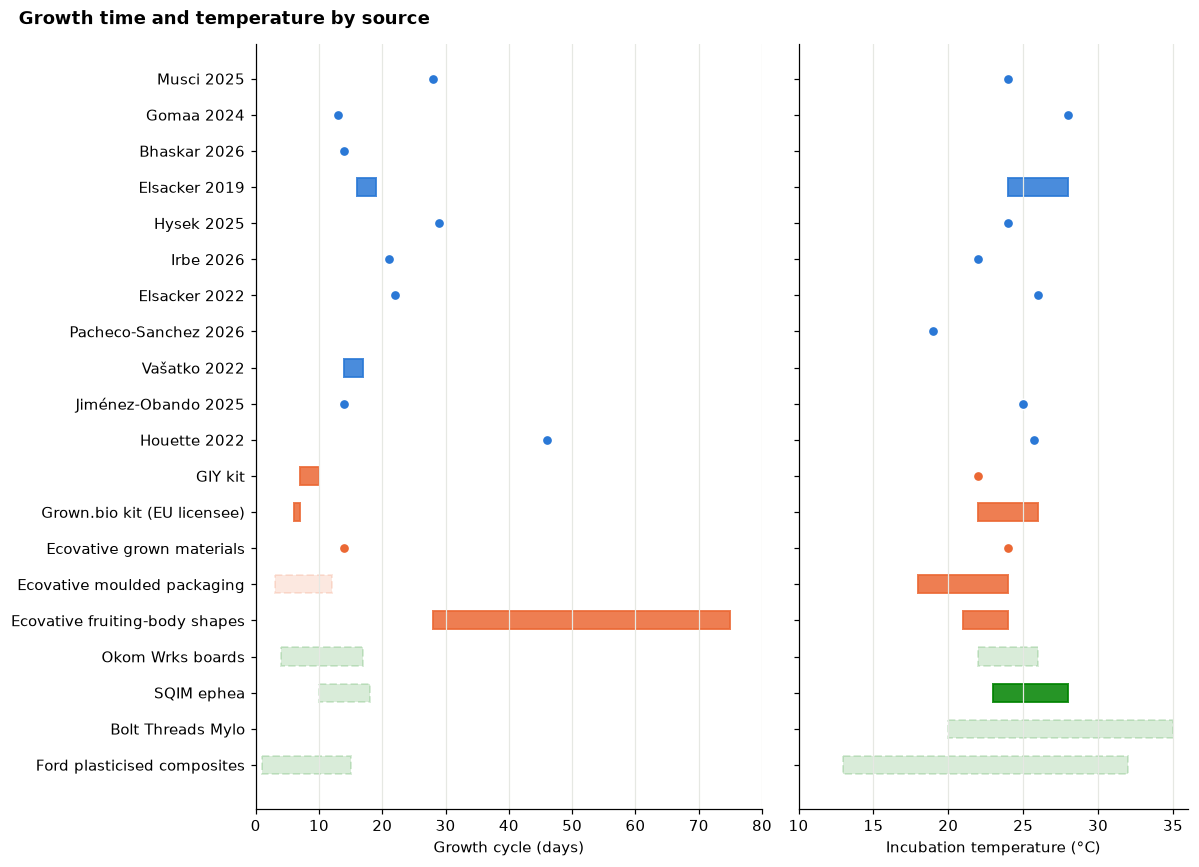

In [8]:
items_d, items_t = [], []
for ds, g in growth.iterrows():
    items_d.append((NAMES.get(ds, ds), g.days_lo, g.days_hi, OURS, False))
    items_t.append((NAMES.get(ds, ds), g.temp_lo, g.temp_hi, OURS, False))
for _, r in shown.dropna(subset=["days_lo", "temp_C_lo"], how="all").iterrows():
    colour, dashed = FAMILY_COLOUR[r.family], r.kind == "claim"
    items_d.append((r.benchmark, r.days_lo, r.days_hi, colour, dashed))  # empty cells draw no bar
    items_t.append((r.benchmark, r.temp_C_lo, r.temp_C_hi, colour, dashed))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 9), sharey=True,
                             gridspec_kw={"width_ratios": [1.3, 1]})
a1.set_xlim(0, 80)
a2.set_xlim(10, 36)
range_rows(a1, items_d, 80)
range_rows(a2, items_t, 36, invert=False)
a1.set_xlabel("Growth cycle (days)")
a2.set_xlabel("Incubation temperature (°C)")
fig.suptitle("Growth time and temperature by source", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**What it shows:** the kits and the packaging patent finish in 3–14 days at 18–26 °C. Most lab studies took 14–29 days, and Houette 2022 took 46. Kits use thin parts and pre-colonised material, so their days are not a fair target for M1a in a 3D mould. Ecovative's fruiting-body shapes (28–75 days) are the one commercial route slower than the lab.

## 5. Tensile strength of leathers

None of our studies measures tensile strength, so mycelium leathers are compared with cow leather and PU artificial leather only.

In [ ]:
items = bench_items("tensile_MPa")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.set_xscale("log")
ax.set_xlim(0.1, 60)
ax.set_xticks([0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50], ["0.1", "0.2", "0.5", "1", "2", "5", "10", "20", "50"])
ax.minorticks_off()
range_rows(ax, items, 60)
ax.set_xlabel("Tensile strength (MPa, log scale)")
ax.set_title("Tensile strength: mycelium leathers against cow leather and PU artificial leather",
             loc="left", fontweight="bold")
plt.show()

**What it shows:** the one independently tested mycelium leather, MuSkin (0.2 MPa), is about 200 times weaker than shoe-upper cow leather (39.5 MPa) and 50 times weaker than PU artificial leather (10.2 MPa), all tested in the same lab (R2). The measured Bolt Threads and BLC mats (2.9 and 3.7 MPa) are about 10 times weaker than leather. Only patent claims (Mylo up to 30 MPa, coated SQIM ephea up to 50) reach leather, and Mylo production paused in 2023. Claims in patents are what the applicant wants to protect, not what they achieved.

## 6. Density against thermal conductivity

Thermal conductivity λ is how easily heat passes through: lower is better insulation. Our extracted tables have no λ yet, so the lab box is Elsacker 2019 (the paper behind our d005), read from the paper.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6.5))
log_axes(ax, [10, 20, 50, 100, 200, 500, 1000, 2500], [0.02, 0.03, 0.05, 0.1, 0.2, 0.5, 0.8])
ax.set(xlabel="Dry density (kg/m³)", ylabel="Thermal conductivity λ (W/m·K)")
ax.axhline(0.026, color="#b0b4b9", lw=1, ls=":")
ax.text(11, 0.0265, "still air ≈ 0.026", fontsize=8, color="#80858c", va="bottom")
draw_benchmarks(ax, "density_kg_m3", "thermal_W_mK", 2500, 0.8, offsets={
    "Elsacker 2019 composites": (4, 3), "Mogu acoustic panels": (8, 4), "Grown.bio packaging": (8, -2),
    "EPS foam (EPS 70–100)": (-10, 14), "XPS board": (4, 3), "PIR board": (4, -14),
    "Expanded cork board": (-82, -12), "Stone wool board": (-34, -24), "Wood fibre board": (4, 3)})
handles = [Line2D([], [], ls="", marker="s", ms=8, color=ECO, label="Ecovative and licensees"),
           Line2D([], [], ls="", marker="s", ms=8, color=OTHER, label="other mycelium companies"),
           Patch(facecolor=OURS, alpha=0.3, edgecolor=OURS, label="lab mycelium (Elsacker 2019)"),
           Patch(facecolor=STANDARD, alpha=0.3, edgecolor=STANDARD, label="conventional material")]
ax.legend(handles=handles, loc="upper left", fontsize=8.5, frameon=False)
ax.set_title("Density against thermal conductivity (lower = better insulation)", loc="left", fontweight="bold")
plt.show()

**What it shows:** mycelium insulates like the natural boards. Elsacker's lab composites (0.040–0.058 W/m·K), Mogu (0.050) and Grown.bio (0.058) sit with cork (0.039), stone wool (0.036) and wood fibre (0.043–0.045), and well ahead of hempcrete, aircrete and brick. Plastic foams (PIR 0.022, XPS 0.030, EPS 0.031) still insulate better at a tenth of the weight. Biohm's claimed 0.024 (not drawn, `no_source`) would beat every natural material and is below still air, which is why it is treated as probably wrong.

## 7. Sound absorption of acoustic panels

αw is a single number from 0 (all sound reflected) to 1 (all absorbed), measured to ISO 11654.

In [ ]:
items = bench_items("alpha_w")
fig, ax = plt.subplots(figsize=(9, 1.8))
ax.set_xlim(0, 1)
range_rows(ax, items, 1)
ax.set_xlabel("Weighted sound absorption αw (0 = reflects all, 1 = absorbs all)")
ax.set_title("Sound absorption of panels mounted directly on the wall", loc="left", fontweight="bold")
plt.show()

**What it shows:** bare Mogu panels (αw 0.30–0.35) absorb about as much echo as bare PET felt panels 9–25 mm thick (0.25–0.50). Both improve with something behind them: Mogu 0.45–0.50 with insulation, felt 0.75–0.90 with an 80 mm gap (see the row notes). Both values come from the makers' own sheets.

## 8. Caveats

- Commercial and conventional values are reference marks without replicates (except the leather tables), never training rows.
- Strain differs: ours, Mogu, Grown.bio and the insulation boards are at 10% (EN 826 or ASTM C165); GIY is at 15%; Okom gives none; wood, aircrete and brick are maximum strength.
- Mogu, Grown.bio and the conventional boards are maker's data sheets (`declared` or maker-measured). Only MuSkin and the two reference leathers (R2) were tested by an independent lab, and that lab's samples came from the German Leather Association.
- Kit and factory cycle days use thin parts and pre-colonised material, so they are not a fair target for the **Colonisation time estimate** in a 3D mould.
- `no_source` rows (Ecovative packaging density and strength, AirMycelium, MycoWorks, Mushroom Material, Biohm, Mykor, Loop) stay in the table only. Biohm's 0.024 W/m·K is below still air and is probably wrong.
- No mycelium "brick" has a published strength: the 2014 Hy-Fi tower (10,000 Ecovative bricks, temporary) gave none, so the brick category holds only hempcrete, aircrete and clay brick.
- Company status changes the meaning of a claim: Mylo production paused in 2023; MycoWorks closed its factory and was liquidated in 2025.
- US20220007777A1 belongs to Bolt Threads and BLC Leather Technology Centre (front page and Google Patents, checked 2026-10-11). Gemini's first sheet wrongly credited it to MycoWorks.
- Four values Gemini credited to the Elsacker 2023 review were checked against it: only the AirMycelium temperature (30–32 °C) is there. AirMycelium density and days, and MycoWorks days, stay `no_source`.

## References

Front-page details checked on Google Patents, Frontiers and grow.bio on 2026-10-11; first compiled by Gemini (`MycoMaterials/Germini/gemini_patent_citations.csv`, `gemini_review_citation.csv`).

**Patents**
- **P1** Bayer, E., & McIntyre, G. (2011). *Method for producing rapidly renewable chitinous material using fungal fruiting bodies and product made thereby* (US8001719B2). Ecovative Design LLC. Filed 2009-06-16, granted 2011-08-23.
- **P2** Bayer, E., & McIntyre, G. (2016). *Method for producing grown materials and products made thereby* (US9485917B2). Ecovative Design LLC. Filed 2007-12-12, granted 2016-11-08.
- **P3** Mueller, P. J., Winiski, J. M., & O'Brien, M. A. (2022). *Process and apparatus for producing mycelium biomaterial* (US11343979B2). Ecovative Design LLC. Filed 2019-05-22, granted 2022-05-31.
- **P4** Wang, J., Bansal Mutalik, R., Smith, M. J., Subler, N. E., Mckenzie, L., Collins, I. S., Flowers, K., Addy, V., Bainbridge, J. M., & Heinrich, M. J. (2022). *Methods of generating mycelium materials with improved properties* (US20220007777A1). Bolt Threads Inc.; BLC Leather Technology Centre Ltd. Filed 2019-11-14, published 2022-01-13.
- **P5** Gandia, A., Cielo, D., Montalti, M., Babbini, S., & Belotti, G. (2021). *Fungal mat coating method and bio-based composite materials obtained therefrom* (WO2021245608A1). Mogu Srl. Filed 2021-06-04, published 2021-12-09.
- **P6** Bakhtiary Davijani, A. A. (2022). *A composite material with enhanced resistance, and methods for production thereof* (WO2022226322A1). Bolt Threads Inc. Filed 2022-04-22, published 2022-10-27.
- **P7** English, J. (2024). *Method for creating a stiff, rigid mycelium-based biocomposite material for use in structural and non-structural applications* (US11866691B2). Okom Wrks Labs PBC. Filed 2021-06-10, granted 2024-01-09.
- **P8** Rocco, C. A., & Kalisz, R. E. (2012). *Plasticized mycelium composite and method* (US8227225B2). Ford Global Technologies LLC. Filed 2010-06-09, granted 2012-07-24.
- **P9** Ross, P. (2016). *Method for producing fungus structures* (US9410116B2). MycoWorks Inc. Filed 2011-11-28, granted 2016-08-09. (No value in the table uses it yet.)

**Review**
- **R1** Elsacker, E., Vandelook, S., & Peeters, E. (2023). Recent technological innovations in mycelium materials as leather substitutes: a patent review. *Frontiers in Bioengineering and Biotechnology*, 11, 1204861. https://doi.org/10.3389/fbioe.2023.1204861

**Maker pages** (accessed 2026-10-11)
- **W1** Ecovative / grow.bio. Grow It Yourself material, product page. https://www.grow.bio/products/grow-it-yourself-material
- **W2** grow.bio. GIY Living Material Instructions. https://grow.bio/pages/giy-living-material-instructions
- **W3** grow.bio. Frequently Asked Questions. https://grow.bio/pages/faqs
- **W4** GROWN bio. *5 Step Grow It Yourself Manual* (2023). Copy hosted by Fabricademy: https://class.textile-academy.org/2024/marion-guillaud/files/week11/grown_bio_grow_it_yourself_manual_23.pdf

**Papers** (added 2026-10-12)
- **R2** Meyer, M., Dietrich, S., Schulz, H., & Mondschein, A. (2021). Comparison of the technical performance of leather, artificial leather, and trendy alternatives. *Coatings*, 11(2), 226. https://doi.org/10.3390/coatings11020226 (CC BY 4.0)
- **R3** Elsacker, E., Vandelook, S., Brancart, J., Peeters, E., & De Laet, L. (2019). Mechanical, physical and chemical characterisation of mycelium-based composites with different types of lignocellulosic substrates. *PLOS ONE*, 14(7), e0213954. https://doi.org/10.1371/journal.pone.0213954 (CC BY 4.0; our d005)

**Mycelium maker data sheets** (accessed 2026-10-12)
- **W5** Mogu. *Mogu Acoustic technical datasheet*. https://mogu.bio/wp-content/uploads/2026/05/Mogu_Acoustic_Technical-Datasheet.pdf
- **W6** Grown.bio. *Material data sheet* (hosted by Solar Impulse). https://solarimpulse.com/companies_file/grown.bio-2.pdf

**Conventional materials** (accessed 2026-10-12; maker data sheets are copyright, numbers cited only)
- **S1** Sundolitt. *Climate EWI (EPS) specification*. https://www.specifiedby.com/sundolitt-ltd/sundolitt-eps/sundolitt-ltd_internal-wall-insulation_specifications_4_bd75cb46-e883-439d-a08d-f0f27c6e28c8.pdf
- **S2** Ravatherm. *XPS X H LB technical data sheet* (v5, 2025). https://www.specifiedby.com/panel-systems-ltd/ravatherm-xps-sheets/ravatherm-xps-x-h-lb-tds-version-5-20250509_2cab80de.pdf
- **S3** Unilin / Utherm. *Utherm Roof LE LS technical data sheet*. https://aem.mohawkind.com/content/dam/insulation/products/brochure-docs/technical-datasheet/utherm/en_DOC_TB_Utherm_Roof_LE_LS.pdf
- **S4** Rockwool. *Fabrock 120 technical data*. https://www.rockwool.com/SysSiteAssets/o2-rockwool/documentation/technical-data-sheets/core-solutions/FABROCK-120-board-insulation-for-oem-applications-Techdata.pdf
- **S5** Steico. *universal dry technical data sheet*. https://cdn.shopify.com/s/files/1/0222/7290/1216/files/STEICO_technical-data-sheet_universal-dry_EUR_en_i.pdf
- **S6** Amorim Cork Solutions. *Expanded insulation corkboard material data sheet*. https://amorimcorksolutions.com/media/10945/tds_expanded-insulation-corkboard_en.pdf
- **S7** Kretschmann, D. E. (2010). Mechanical properties of wood. In *Wood Handbook* (FPL-GTR-190), chapter 5, Tables 5-3a and 5-5a. USDA Forest Products Laboratory (US government work, public domain). https://www.fpl.fs.usda.gov/documnts/fplgtr/fplgtr190/chapter_05.pdf
- **S8** H+H UK. *Solar Grade Jumbo Block* (NBS Source). https://source.thenbs.com/en/gb/product/solar-grade-jumbo-block/rJfRGbyzYaNhQB4rGBcK7C/owKb17agwo8VpZENxdzgKH
- **S9** Floren. *Brigand clay brick* (NBS Source). https://source.thenbs.com/en/product/floren-brigand-clay-brick/dRJoZDo1W74ntvqT99Gi9h/4w356KQf9bU4xaD3MBLzvA
- **S10** Wikipedia. *Hempcrete* (accessed 2026-10-12; secondary, cites Bouloc 2013, Niyigena 2016, Dhakal 2016). https://en.wikipedia.org/wiki/Hempcrete
- **S11** XAL. *Xilence felt material overview*. https://www.xal.com/downloads/Datasheets/xilence_data_sheet_felt_material_overview_EN.pdf